<a href="https://colab.research.google.com/github/GavrilLaura/PMP-2026/blob/main/Lab04/pmp_tema3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tema 3 - laborator 4
**Reţele Bayesiene**

**Ex. 1.** În documentaţia pgmpy (https://pgmpy.org/examples/Monty_Hall.html) găsiţi formularea şi implementarea celebrei probleme Monty Hall. Cerinţa acestui exerciţiu este să explicaţi problema şi codul din implementare.

**Problema Monty Hall**

La un concurs sunt 3 usi: in spatele uneia se afla o masina, in spatele celorlalte doua cate o capra. Concurentul alege o usa. Prezentatorul, care stie unde este masina, deschide una dintre celelalte doua usi, mereu una cu o capra, si ii ofera concurentului posibilitatea de a schimba alegerea. Intrebarea este daca merita sa schimbe.

Modelam problema printr-o retea Bayesiana cu trei variabile: usa aleasa de concurent ($C$), usa cu premiul ($P$) si usa deschisa de prezentator ($H$). Reteaua are forma $C$ -> $H$ <- $P$, deoarece alegerea prezentatorului depinde atat de usa concurentului, cat si de usa cu premiul: el nu le poate deschide pe niciuna dintre ele. $H$ este un collider, asa ca $C$ si $P$ sunt independente initial, dar devin dependente dupa ce observam ce usa a deschis prezentatorul. Cu VariableElimination calculam probabilitatea ca premiul sa fie in spatele fiecarei usi, stiind alegerea concurentului si usa deschisa.

In concluzie, merita sa schimbe: probabilitatea de castig creste de la 1/3 la 2/3. Intuitiv, prima alegere este gresita in 2/3 din cazuri, iar atunci prezentatorul este fortat sa lase inchisa exact usa cu masina.

In [ ]:
!pip install pgmpy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 65.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 162.6/162.6 kB 12.8 MB/s eta 0:00:00


In [ ]:
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.factors.discrete import TabularCPD
from pgmpy.inference import VariableElimination

model = DiscreteBayesianNetwork([("C", "H"), ("P", "H")])

cpd_c = TabularCPD("C", 3, [[0.33], [0.33], [0.33]])
cpd_p = TabularCPD("P", 3, [[0.33], [0.33], [0.33]])
cpd_h = TabularCPD(
    "H",
    3,
    [
        [0, 0, 0, 0, 0.5, 1, 0, 1, 0.5],
        [0.5, 0, 1, 0, 0, 0, 1, 0, 0.5],
        [0.5, 1, 0, 1, 0.5, 0, 0, 0, 0],
    ],
    evidence=["C", "P"],
    evidence_card=[3, 3],
)

model.add_cpds(cpd_c, cpd_p, cpd_h)

infer = VariableElimination(model)
posterior_p = infer.query(["P"], evidence={"C": 0, "H": 2})
print(posterior_p)

/usr/local/lib/python3.13/dist-packages/pgmpy/estimators/__init__.py:4: FutureWarning: `pgmpy.estimators.StructureScore` is deprecated and will be removed in v1.3.0. Use `pgmpy.structure_score` instead.
  from .StructureScore import (


+------+----------+
| P    |   phi(P) |
+======+==========+
| P(0) |   0.3333 |
+------+----------+
| P(1) |   0.6667 |
+------+----------+
| P(2) |   0.0000 |
+------+----------+


**Ex. 2.** Un medic doreşte să determine probabilitatea ca un pacient să aibă o anumită boală pulmonară (B), având în vedere simptomele observate. Există trei variabile observabile care pot indica prezenţa bolii: tuse (T), dificultate de respiraţie (D), radiografie anormală (X). Toate acestea sunt variabile binare.
De asemenea, ştim că:
* Dacă pacientul are boala (B), există o probabilitate ridicată să aibă tuse şi să apară anomalii la radiografie.
* Dificultatea de respiraţie (D) este dependentă atât de prezenţa bolii pulmonare (B), cât şi de prezenţa tusei (T).

Astfel, datele de probabilitate condiţionată sunt următoarele:
1. Probabilitatea apriori pentru boala pulmonară:

    P(B = 1) = 0.1,
    
    P(B = 0) = 0.9;

2. Probabilitatea condiţionată pentru tuse (T) condiţionată de boală (B):

    P(T = 1∣B = 1) = 0.8,
    
    P(T = 1∣B = 0) = 0.3;

3. Probabilitatea condiţionată pentru radiografie anormală (X) condiţionată de boală (B):

    P(X = 1∣B = 1) = 0.9,
    
    P(X = 1∣B = 0) = 0.1;

4. Probabilitatea condiţionată pentru dificultate de respiraţie (D), condiţionată de boală (B) şi tuse (T):

    P(D = 1∣B = 1,T = 1) = 0.9,
    
    P(D = 1∣B = 1,T = 0) = 0.4;

    P(D = 1∣B = 0,T = 1) = 0.5,
    
    P(D = 1∣B = 0,T = 0) = 0.1.

**a)** Definiti modelul probabilist, folosind pgmpy, care sa descrie contextul de mai sus.

**b)** Medicul observă că pacientul are tuse şi dificultăţi de respiraţie. Determinaţi probabilitatea ca pacientul să aibă boala pulmonară.

**c)** Ulterior se descoperă (cu alte mijloace) că pacientul nu avea boala pulmonară. Care este probabilitatea ca radiografia să fi fost anormală?

**d)** Calculaţi cele 2 probabilităţi folosind regula lui Bayes şi incărcaţi calculul fie în Markdown/Latex, fie ca foto
la foia de lucru (indicaţie: puteţi să vă folosiţi de independenţele condiţionale rezultate din modelul de reţea
bayesiană)

Model valid: True
(D ⟂ X | B, T)
(T ⟂ X | B)
(X ⟂ D, T | B)


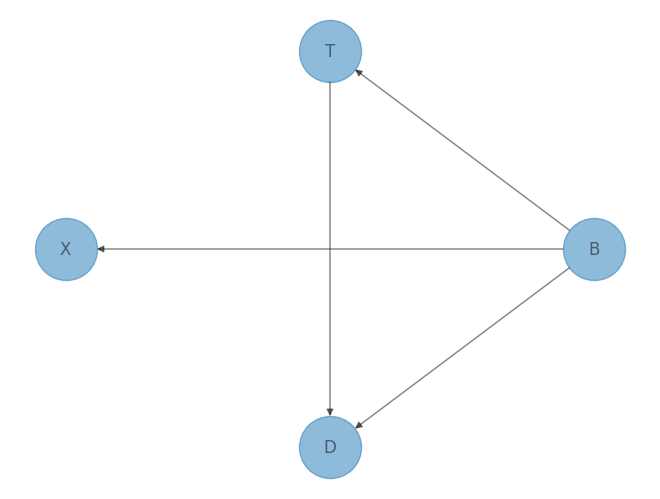

In [ ]:
#a)

from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.factors.discrete import TabularCPD
from pgmpy.inference import VariableElimination
import networkx as nx
import matplotlib.pyplot as plt

model = DiscreteBayesianNetwork([("B", "T"), ("B", "X"), ("B", "D"), ("T", "D")])

cpd_b = TabularCPD("B", 2, [[0.9], [0.1]])

cpd_t = TabularCPD(
    "T", 2,
    [[0.7, 0.2],
     [0.3, 0.8]],
    evidence=["B"], evidence_card=[2],
)

cpd_x = TabularCPD(
    "X", 2,
    [[0.9, 0.1],
     [0.1, 0.9]],
    evidence=["B"], evidence_card=[2],
)

cpd_d = TabularCPD(
    "D", 2,
    [[0.9, 0.5, 0.6, 0.1],
     [0.1, 0.5, 0.4, 0.9]],
    evidence=["B", "T"], evidence_card=[2, 2],
)

model.add_cpds(cpd_b, cpd_t, cpd_x, cpd_d)
print("Model valid:", model.check_model())

print(model.local_independencies(["B", "T", "X", "D"]))

pos = nx.circular_layout(model)
nx.draw(model, with_labels=True, pos=pos, alpha=0.5, node_size=2000)
plt.show()

In [ ]:
#b)

infer = VariableElimination(model)

posterior_b = infer.query(["B"], evidence={"T": 1, "D": 1})
print(posterior_b)

+------+----------+
| B    |   phi(B) |
+======+==========+
| B(0) |   0.6522 |
+------+----------+
| B(1) |   0.3478 |
+------+----------+


In [ ]:
# c)

posterior_x = infer.query(["X"], evidence={"B": 0, "T": 1, "D": 1})
print(posterior_x)


+------+----------+
| X    |   phi(X) |
+======+==========+
| X(0) |   0.9000 |
+------+----------+
| X(1) |   0.1000 |
+------+----------+


### d)
Factorizarea: P(B, T, X, D) = P(B) · P(T | B) · P(X | B) · P(D | B, T)

**b)** X nu este observat și se elimină prin însumare (Σ_x P(x | B) = 1):

$$P(B=1 \mid T=1, D=1) = \frac{P(B=1)P(T=1|B=1)P(D=1|B=1,T=1)}{\sum_{b} P(b)P(T=1|b)P(D=1|b,T=1)} = \frac{0.1 \cdot 0.8 \cdot 0.9}{0.1 \cdot 0.8 \cdot 0.9 + 0.9 \cdot 0.3 \cdot 0.5} = \frac{0.072}{0.207} \approx 0.348$$

**c)** În rețea, X ⊥ (T, D) | B (toate drumurile de la X la T și D trec prin B, care nu e collider). Deci:

$$P(X=1 \mid B=0, T=1, D=1) = P(X=1 \mid B=0) = 0.1$$

**Ex. 3.** Un joc între doi jucători, J0 şi J1, se desfăşoară în felul următor:
* se aruncă mai întâi cu o monedă (normală) pentru a decide cine începe: J0 sau J1;

* în prima rundă, jucătorul desemnat aruncă cu propriul zar; fie n numărul obţinut;

* în a doua rundă, celălalt jucător aruncă cu moneda proprie de 2n ori; fie m numărul de steme obţinute.

Jucătorul din prima rundă câştigă dacă n ≥ m, în caz contrar câştigând jucătorul din a doua rundă. Mai ştim că jucătorul J1 este necinstit, el aducând o monedă măsluită, cu probabilitatea de obţinere a stemei egală cu 4/7. În schimb, moneda jucătorului J0 este normală, iar cele două zaruri sunt şi ele normale.

**a)** Estimaţi care dintre cei doi jucători are şansele cele mai mari de câştig, simulând un joc de 10000 ori.

**b)** Folosind pgmpy, definiţi o reţea Bayesiană care sa descrie contextul de mai sus.

**c)** Folosind modelul de mai sus, determinaţi cine e cel mai probabil să fi început jocul, ştiind că în a doua rundă s-a
obţinut o singură stemă.

In [ ]:
#a)

import random

def joc():
    primul = random.choice([0, 1])
    al_doilea = 1 - primul

    n = random.randint(1, 6)

    if al_doilea == 1:
        p_stema = 4/7
    else:
        p_stema = 1/2

    m = 0
    for aruncare in range(2 * n):
        x = random.random()
        if x < p_stema:
            m = m + 1

    if n >= m:
        return primul
    else:
        return al_doilea

N = 10000
castiguri = [0, 0]
for i in range(N):
    castiguri[joc()] += 1

print(f"J0 a castigat {castiguri[0]} jocuri ({castiguri[0] / N:.2%})")
print(f"J1 a castigat {castiguri[1]} jocuri ({castiguri[1] / N:.2%})")

J0 a castigat 4212 jocuri (42.12%)
J1 a castigat 5788 jocuri (57.88%)


Model valid: True


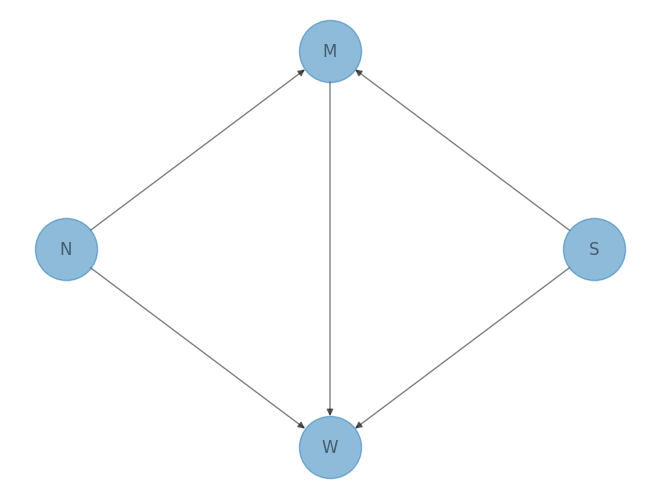

In [ ]:
#c)

from math import comb
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.factors.discrete import TabularCPD
import networkx as nx
import matplotlib.pyplot as plt

# S = cine incepe
# N = zarul
# M = numarul de steme
# W = castigatorul

model = DiscreteBayesianNetwork([("S", "M"), ("N", "M"),
                                 ("S", "W"), ("N", "W"), ("M", "W")])

cpd_s = TabularCPD("S", 2, [[0.5], [0.5]])

cpd_n = TabularCPD("N", 6, [[1/6], [1/6], [1/6], [1/6], [1/6], [1/6]])

valori_m = []
for m in range(13):
    rand = []
    for s in [0, 1]:
        p = 4/7 if s == 0 else 1/2
        for n in range(1, 7):
            if m <= 2 * n:
                rand.append(comb(2 * n, m) * p**m * (1 - p)**(2 * n - m))
            else:
                rand.append(0)
    valori_m.append(rand)

cpd_m = TabularCPD("M", 13, valori_m,
                   evidence=["S", "N"], evidence_card=[2, 6])

w0, w1 = [], []
for s in [0, 1]:
    for n in range(1, 7):
        for m in range(13):
            castigator = s if n >= m else 1 - s
            w0.append(1 if castigator == 0 else 0)
            w1.append(1 if castigator == 1 else 0)

cpd_w = TabularCPD("W", 2, [w0, w1],
                   evidence=["S", "N", "M"], evidence_card=[2, 6, 13])

model.add_cpds(cpd_s, cpd_n, cpd_m, cpd_w)
print("Model valid:", model.check_model())

pos = nx.circular_layout(model)
nx.draw(model, with_labels=True, pos=pos, alpha=0.5, node_size=2000)
plt.show()

In [ ]:
#c)

from pgmpy.inference import VariableElimination

infer = VariableElimination(model)

posterior_s = infer.query(["S"], evidence={"M": 1})
print(posterior_s)

+------+----------+
| S    |   phi(S) |
+======+==========+
| S(0) |   0.4529 |
+------+----------+
| S(1) |   0.5471 |
+------+----------+
